In [41]:
import numpy as np
import pandas as pd

In [42]:
def load_mean_adj(graph_path, label_path):
    graphs = np.load(graph_path)
    adj = graphs.mean(axis=0)
    df = pd.read_csv(label_path)
    labels = df.iloc[:, 0].astype(str).str.strip().values
    return adj, labels


A1, L1 = load_mean_adj(
    './result/wo_layer/stage1/tuning/bs8_dp0.1_sw1.0/dynamic_full_graphs.npy',
    './result/wo_layer/stage1/df_scaled.csv'
)

A2, L2 = load_mean_adj(
    './result/wo_layer/stage2/tuning/bs64_dp0.8_sw1.0/dynamic_full_graphs.npy',
    './result/wo_layer/stage2/df_scaled.csv'
)

A3, L3 = load_mean_adj(
    './result/wo_layer/stage3/tuning/bs32_dp0.8_sw1.0/dynamic_full_graphs.npy',
    './result/wo_layer/stage3/df_scaled.csv'
)


## 1. Validation

In [43]:
def classify_pairs(adjA, adjB, labels, nameA="A", nameB="B"):
    n = adjA.shape[0]

    # sign(A) * sign(B) = -1 
    signA = np.sign(adjA)
    signB = np.sign(adjB)

    flip_mask = (signA * signB == -1)

    flip_pairs = []
    for i in range(n):
        for j in range(n):
            if flip_mask[i, j]:
                flip_pairs.append({
                    "source": labels[i],
                    "target": labels[j],
                    f"{nameA}_weight": adjA[i, j],
                    f"{nameB}_weight": adjB[i, j],
                    "difference": adjA[i, j] - adjB[i, j]
                })

    df_flip = pd.DataFrame(flip_pairs)

    same_mask = (signA * signB == 1) & (signA != 0)

    same_pairs = []
    for i in range(n):
        for j in range(n):
            if same_mask[i, j]:
                same_pairs.append({
                    "source": labels[i],
                    "target": labels[j],
                    f"{nameA}_weight": adjA[i, j],
                    f"{nameB}_weight": adjB[i, j],
                    "difference": adjA[i, j] - adjB[i, j]
                })

    df_same = pd.DataFrame(same_pairs)

    return df_flip, df_same

df_12_flip, df_12_same = classify_pairs(A1, A2, L1, nameA="A1", nameB="A2")
df_13_flip, df_13_same = classify_pairs(A1, A3, L1, nameA="A1", nameB="A3")
df_23_flip, df_23_same = classify_pairs(A2, A3, L2, nameA="A2", nameB="A3")

In [44]:
def evaluate_source_plasticity(df_flip, df_same, A1=None, A2=None, labels=None, nameA="A", nameB="B"):
    all_sources = pd.concat([df_flip, df_same])["source"].unique()
    results = []

    if A1 is not None and A2 is not None and labels is not None:
        label_to_idx = {lab: i for i, lab in enumerate(labels)}

        dot = np.sum(A1 * A2, axis=1)
        norm1 = np.linalg.norm(A1, axis=1)
        norm2 = np.linalg.norm(A2, axis=1)
        cos_sim = np.divide(dot, norm1 * norm2, out=np.zeros_like(dot), where=(norm1 * norm2) != 0)
        NCC_all = 1 - cos_sim  # full vector

        # Precompute WSFR
        sign1 = np.sign(A1)
        sign2 = np.sign(A2)
        flip_mask_mat = (sign1 * sign2 == -1)
        delta = np.abs(A1 - A2)

        # numerator, denominator for each source node
        WSFR_num = np.sum(delta * flip_mask_mat, axis=1)
        WSFR_denom = np.sum(np.abs(A1) + np.abs(A2), axis=1)
        WSFR_all = np.divide(WSFR_num, WSFR_denom,
                             out=np.zeros_like(WSFR_num),
                             where=WSFR_denom != 0)
    else:
        NCC_all = None
        WSFR_all = None

    for s in all_sources:

        df_flip_s = df_flip[df_flip["source"] == s]
        df_same_s = df_same[df_same["source"] == s]

        flip_count = len(df_flip_s)
        same_count = len(df_same_s)
        total = flip_count + same_count

        # ---------- NRB ----------
        if flip_count > 0:
            flip_to_exc = (df_flip_s[f"{nameA}_weight"] < 0) & (df_flip_s[f"{nameB}_weight"] > 0)
            flip_to_inh = (df_flip_s[f"{nameA}_weight"] > 0) & (df_flip_s[f"{nameB}_weight"] < 0)
            num_exc = flip_to_exc.sum()
            num_inh = flip_to_inh.sum()
        else:
            num_exc = num_inh = 0

        # ---------- Flip Strength ----------
        if flip_count > 0:
            flip_strength = np.mean(np.abs(df_flip_s[f"{nameA}_weight"] - df_flip_s[f"{nameB}_weight"]))
        else:
            flip_strength = 0

        # ---------- NCC & WSFR ----------
        if NCC_all is not None:
            idx = label_to_idx[s]
            NCC = NCC_all[idx]
            WSFR = WSFR_all[idx]
        else:
            NCC = None
            WSFR = None

        results.append({
            "source": s,
            "flip_count": flip_count,
            "same_count": same_count,
            "total_nonzero": total,
            "SFR": flip_count / total if total > 0 else 0,
            "SSR": same_count / total if total > 0 else 0,
            "NRB": num_exc - num_inh,
            "FlipStrength": flip_strength,
            "WSFR": WSFR,
            "NCC": NCC
        })

    return pd.DataFrame(results).sort_values("SFR", ascending=False)




df_source_12 = evaluate_source_plasticity(
    df_12_flip, df_12_same,
    A1=A1, A2=A2, labels=L1,
    nameA="A1", nameB="A2"
)
df_source_13 = evaluate_source_plasticity(
    df_13_flip, df_13_same,
    A1=A1, A2=A3, labels=L1,
    nameA="A1", nameB="A3"
)
df_source_23 = evaluate_source_plasticity(
    df_23_flip, df_23_same,
    A1=A2, A2=A3, labels=L2,
    nameA="A2", nameB="A3"
)

In [45]:
df_source_12

,source,flip_count,same_count,total_nonzero,SFR,SSR,NRB,FlipStrength,WSFR,NCC
38,AAA,1,0,1,1.0,0.0,1,0.173405,1.000000,2.000000e+00
32,PIR,1,0,1,1.0,0.0,-1,1.393625,1.000000,2.000000e+00
0,FRP,1,1,2,0.5,0.5,1,1.428518,0.537496,1.090141e+00
19,ACAd,2,2,4,0.5,0.5,2,0.540014,0.413203,6.485824e-01
37,OT,1,1,2,0.5,0.5,1,0.466784,0.189239,1.033306e-01
...,...,...,...,...,...,...,...,...,...,...
62,TR,0,2,2,0.0,1.0,0,0.000000,0.000000,3.816961e-07
63,ENTl,0,3,3,0.0,1.0,0,0.000000,0.000000,6.742840e-04
72,PVT,0,6,6,0.0,1.0,0,0.000000,0.000000,1.374744e-02
73,CM,0,9,9,0.0,1.0,0,0.000000,0.000000,2.146654e-02


In [46]:
import nrrd
from iblatlas.regions import BrainRegions

df_nt = pd.read_csv("../transcriptome/merfish/neurotransmitter_fraction.csv",index_col=0)

annotation, _ = nrrd.read("../ccf-v3/annotation_25.nrrd")
ids, counts = np.unique(annotation, return_counts=True)

volume = pd.DataFrame({
    "atlas_id": ids,
    "volume": counts * 25**3 / 1e9
})

df_nt["atlas_id"] = df_nt["atlas_id"].abs().astype(int)

voxel_volume = 25**3 / 1e9

volume_dict = {
    int(i): c * voxel_volume
    for i, c in zip(ids, counts)
    if i != 0
}

br = BrainRegions()

parent_to_children = {}

for child, parent in zip(
    np.abs(br.id),
    np.abs(br.parent)
):

    if np.isnan(child) or np.isnan(parent):
        continue

    parent_to_children.setdefault(int(parent),[]).append(int(child))


def get_descendants(region_id):

    children = parent_to_children.get(region_id,[])

    if len(children) == 0:
        return [region_id]

    leaves = []

    for child in children:
        leaves.extend(get_descendants(child))

    return leaves


def get_volume(region_id):
    if region_id in volume_dict:
        return volume_dict[region_id]

    leaf_ids = get_descendants(region_id)

    return sum(volume_dict.get(leaf_id,0) for leaf_id in leaf_ids)

df_nt["volume"] = (df_nt["atlas_id"].apply(get_volume))

df_nt

,Chol,Dopa,GABA,GABA-Glyc,Glut,Glut-GABA,Nora,Sero,cell_number,atlas_id,volume
AAA,0.026902,0.0,0.736864,0.000420,0.231610,0.004203,0.0,0.0,4803,23,0.494563
ACAd,0.000000,0.0,0.118460,0.000000,0.880990,0.000550,0.0,0.0,21159,39,6.259563
ACAv,0.000000,0.0,0.091720,0.000000,0.907890,0.000390,0.0,0.0,24178,48,4.820094
ACB,0.007831,0.0,0.986176,0.000000,0.004522,0.001471,0.0,0.0,34652,56,4.398266
AId,0.000000,0.0,0.132951,0.000000,0.866645,0.000404,0.0,0.0,18153,104,7.452687
...,...,...,...,...,...,...,...,...,...,...,...
VM,0.000000,0.0,0.040731,0.000522,0.958747,0.000000,0.0,0.0,4401,685,0.926547
VPL,0.000000,0.0,0.055556,0.000000,0.944444,0.000000,0.0,0.0,4750,718,0.876734
VPLpc,0.000000,0.0,0.017182,0.000000,0.982818,0.000000,0.0,0.0,548,725,0.098844
VPM,0.000000,0.0,0.005398,0.000000,0.994602,0.000000,0.0,0.0,10820,733,1.644719


In [47]:
def calculate_category_proportions(row):
    excitatory_sum = sum([row[col] for col in ["Glut"] if row[col] > 0])
    inhibitory_sum = sum([row[col] for col in ["GABA-Glyc", "GABA"] if row[col] > 0])
    modulatory_sum = sum([row[col] for col in ["Chol", "Dopa", "Nora", "Sero", "Glut-GABA"] if row[col] > 0])

    total = excitatory_sum + inhibitory_sum + modulatory_sum
    if total == 0: 
        return {"Excitatory": 0, "Inhibitory": 0, "Modulatory": 0}
    
    return {
        "Excitatory": excitatory_sum / total,
        "Inhibitory": inhibitory_sum / total,
        "Modulatory": modulatory_sum / total
    }

def calculate_non_dominance_std(row):

    p_exc = row["Excitatory"]
    p_inh = row["Inhibitory"]
    p_mod = row["Modulatory"]
    
    proportions = [p_exc, p_inh, p_mod]
    return np.std(proportions)

def calculate_non_dominance_max(row):
    p_exc = row["Excitatory"] 
    p_inh = row["Inhibitory"]
    p_mod = row["Modulatory"]
    return 1 - max(p_exc+p_mod, p_inh+p_mod)

def calculate_dominance_max(row, exc_weight=1, inh_weight=1.1):
    p_exc = row["Excitatory"] * exc_weight  
    p_inh = row["Inhibitory"] * inh_weight  
    p_mod = row["Modulatory"]

    return max(p_exc + p_mod, p_inh + p_mod)


def calculate_Shannon_Entropy(row):
    p_exc = row["Excitatory"]
    p_inh = row["Inhibitory"]
    p_mod = row["Modulatory"]

    p = np.array([p_exc, p_inh, p_mod])
    
    p = p[p > 0]

    return -np.sum(p * np.log(p))


def calculate_gini(row):
    p_exc = row["Excitatory"]
    p_inh = row["Inhibitory"]
    p_mod = row["Modulatory"]
    
    proportions = [p_exc, p_inh, p_mod]
    gini = 1 - sum(p ** 2 for p in proportions)
    
    return gini

In [48]:
df_merge_12 = df_source_12.merge(df_nt, left_on="source", right_index=True, how="left")
df_source_12_sorted = df_merge_12.sort_values("SFR", ascending=False)
df_source_12_sorted[["Excitatory", "Inhibitory", "Modulatory"]] = df_source_12_sorted.apply(
    calculate_category_proportions, axis=1, result_type="expand"
)
df_source_12_sorted["Non_Dominance_Max"] = df_source_12_sorted.apply(calculate_non_dominance_max, axis=1)
df_source_12_sorted["Dominance_Max"] = df_source_12_sorted.apply(calculate_dominance_max, axis=1)
df_source_12_sorted["Shannon_Entropy"] = df_source_12_sorted.apply(calculate_Shannon_Entropy, axis=1)
#df_source_12_sorted["Gini"] = df_source_12_sorted.apply(calculate_gini, axis=1)
df_source_12_sorted[["source", "SFR", "Excitatory", "Inhibitory", "Modulatory", "Shannon_Entropy","cell_number","volume"]]

,source,SFR,Excitatory,Inhibitory,Modulatory,Shannon_Entropy,cell_number,volume
32,PIR,1.0,0.862519,0.135740,0.001740,0.409697,69761,11.565656
38,AAA,1.0,0.231610,0.737285,0.031106,0.671434,4803,0.494563
19,ACAd,0.5,0.880990,0.118460,0.000550,0.368454,21159,6.259563
0,FRP,0.5,0.840650,0.158808,0.000542,0.442211,2581,1.944594
37,OT,0.5,0.005604,0.989165,0.005231,0.067310,22538,3.819063
...,...,...,...,...,...,...,...,...
67,ACB,0.0,0.004522,0.986176,0.009302,0.081652,34652,4.398266
71,AM,0.0,0.938838,0.059633,0.001529,0.237303,2424,0.821531
72,PVT,0.0,0.994775,0.005225,0.000000,0.032665,5160,0.444219
73,CM,0.0,1.000000,0.000000,0.000000,-0.000000,1676,0.249766


In [49]:
df_merge_13 = df_source_13.merge(df_nt, left_on="source", right_index=True, how="left")
df_source_13_sorted = df_merge_13.sort_values("SFR", ascending=False)
df_source_13_sorted[["Excitatory", "Inhibitory", "Modulatory"]] = df_source_13_sorted.apply(
    calculate_category_proportions, axis=1, result_type="expand"
)
df_source_13_sorted["Non_Dominance_Max"] = df_source_13_sorted.apply(calculate_non_dominance_max, axis=1)
df_source_13_sorted["Shannon_Entropy"] = df_source_13_sorted.apply(calculate_Shannon_Entropy, axis=1)
df_source_13_sorted["Dominance_Max"] = df_source_13_sorted.apply(calculate_dominance_max, axis=1)
df_source_13_sorted[["source", "SFR", "Excitatory", "Inhibitory", "Modulatory", "Shannon_Entropy","cell_number","volume"]]

,source,SFR,Excitatory,Inhibitory,Modulatory,Shannon_Entropy,cell_number,volume
40,AAA,1.000000,0.231610,0.737285,0.031106,0.671434,4803,0.494563
34,PIR,1.000000,0.862519,0.135740,0.001740,0.409697,69761,11.565656
29,RSPv,0.526316,0.881536,0.118278,0.000186,0.365238,40209,8.699750
20,ACAd,0.500000,0.880990,0.118460,0.000550,0.368454,21159,6.259563
0,FRP,0.500000,0.840650,0.158808,0.000542,0.442211,2581,1.944594
...,...,...,...,...,...,...,...,...
66,SUB,0.000000,0.854244,0.144828,0.000928,0.420892,15435,2.103578
70,BST,0.000000,0.094437,0.855962,0.049601,0.504970,10756,1.340500
72,AM,0.000000,0.938838,0.059633,0.001529,0.237303,2424,0.821531
73,PVT,0.000000,0.994775,0.005225,0.000000,0.032665,5160,0.444219


In [50]:
df_merge_23 = df_source_23.merge(df_nt, left_on="source", right_index=True, how="left")
df_source_23_sorted = df_merge_23.sort_values("SFR", ascending=False)
df_source_23_sorted[["Excitatory", "Inhibitory", "Modulatory"]] = df_source_23_sorted.apply(
    calculate_category_proportions, axis=1, result_type="expand"
)
df_source_23_sorted["Non_Dominance_Max"] = df_source_23_sorted.apply(calculate_non_dominance_max, axis=1)
df_source_23_sorted["Shannon_Entropy"] = df_source_23_sorted.apply(calculate_Shannon_Entropy, axis=1)
df_source_23_sorted["Dominance_Max"] = df_source_23_sorted.apply(calculate_dominance_max, axis=1)

#df_source_23_sorted["Balance_Exc_Inh"] = 1 - abs(df_source_23_sorted["Excitatory"] - df_source_23_sorted["Inhibitory"])
#df_source_23_sorted["Plasticity_Score"] = df_source_23_sorted["Balance_Exc_Inh"] * df_source_23_sorted["Modulatory"]

df_source_23_sorted[df_source_23_sorted['SFR']>0][["source", "SFR", "Excitatory", "Inhibitory", "Modulatory", "Shannon_Entropy","cell_number","volume"]]

,source,SFR,Excitatory,Inhibitory,Modulatory,Shannon_Entropy,cell_number,volume
7,VISpm,0.166667,0.891914,0.107673,0.000413,0.345203,6202,2.089344
9,AIv,0.166667,0.891697,0.107100,0.001203,0.349565,6492,3.471875
15,VAL,0.125000,0.951062,0.048938,0.000000,0.195375,3403,0.817406
10,RSPagl,0.125000,0.881339,0.117931,0.000731,0.368697,18438,4.710719
23,CM,0.111111,1.000000,0.000000,0.000000,-0.000000,1676,0.249766
18,VPM,0.103448,0.994602,0.005398,0.000000,0.033571,10820,1.644719
19,VPMpc,0.100000,0.976532,0.023468,0.000000,0.111245,1375,0.214313
22,SMT,0.100000,0.993671,0.006329,0.000000,0.038351,1385,0.307531
6,AUDp,0.100000,0.870843,0.128330,0.000827,0.389781,15636,4.303625
5,VISC,0.095238,0.832680,0.166052,0.001268,0.459068,12707,4.706844


In [120]:
df_combined = pd.concat([df_source_12_sorted, df_source_13_sorted, df_source_23_sorted], axis=0, ignore_index=True)
df_combined = df_combined[df_combined['SFR']>0]
df_combined = df_combined[df_combined['FlipStrength']>0]
df_combined = df_combined[df_combined['total_nonzero']>0]
df_combined = df_combined.loc[
    df_combined.groupby("source")["WSFR"].idxmax()
].reset_index(drop=True)

In [121]:
df_combined

,source,flip_count,same_count,total_nonzero,SFR,SSR,NRB,FlipStrength,WSFR,NCC,...,Sero,cell_number,atlas_id,volume,Excitatory,Inhibitory,Modulatory,Non_Dominance_Max,Dominance_Max,Shannon_Entropy
0,AAA,1,0,1,1.000000,0.000000,1,0.173405,1.000000,2.000000,...,0.000000,4803,23,0.494563,0.231610,0.737285,0.031106,0.231610,0.842119,0.671434
1,ACAd,2,2,4,0.500000,0.500000,2,0.499772,0.420459,0.745220,...,0.000000,21159,39,6.259563,0.880990,0.118460,0.000550,0.118460,0.881540,0.368454
2,ACAv,1,7,8,0.125000,0.875000,-1,0.627372,0.083045,0.076655,...,0.000000,24178,48,4.820094,0.907890,0.091720,0.000390,0.091720,0.908280,0.309913
3,AId,3,18,21,0.142857,0.857143,1,0.399749,0.094996,0.138760,...,0.000000,18153,104,7.452687,0.866645,0.132951,0.000404,0.132951,0.867049,0.395459
4,AIp,1,7,8,0.125000,0.875000,1,0.344327,0.067338,0.058988,...,0.000000,11362,111,4.870281,0.843035,0.155270,0.001695,0.155270,0.844730,0.443966
5,AIv,2,4,6,0.333333,0.666667,2,0.975582,0.412888,0.638042,...,0.000000,6492,119,3.471875,0.891697,0.107100,0.001203,0.107100,0.892900,0.349565
6,AUDp,1,9,10,0.100000,0.900000,-1,0.304547,0.040170,0.022223,...,0.000000,15636,1002,4.303625,0.870843,0.128330,0.000827,0.128330,0.871670,0.389781
7,AUDv,9,12,21,0.428571,0.571429,7,0.504116,0.463709,1.233332,...,0.000000,13279,1018,3.645531,0.854861,0.144408,0.000731,0.144408,0.855592,0.418781
8,CA1,1,2,3,0.333333,0.666667,1,1.888899,0.323596,0.627667,...,0.000000,56424,382,10.209234,0.852943,0.142745,0.004312,0.142745,0.857255,0.437038
9,CLA,6,27,33,0.181818,0.818182,4,0.685114,0.213379,0.561441,...,0.000000,4997,583,0.551297,0.902860,0.096060,0.001079,0.096060,0.903940,0.324683


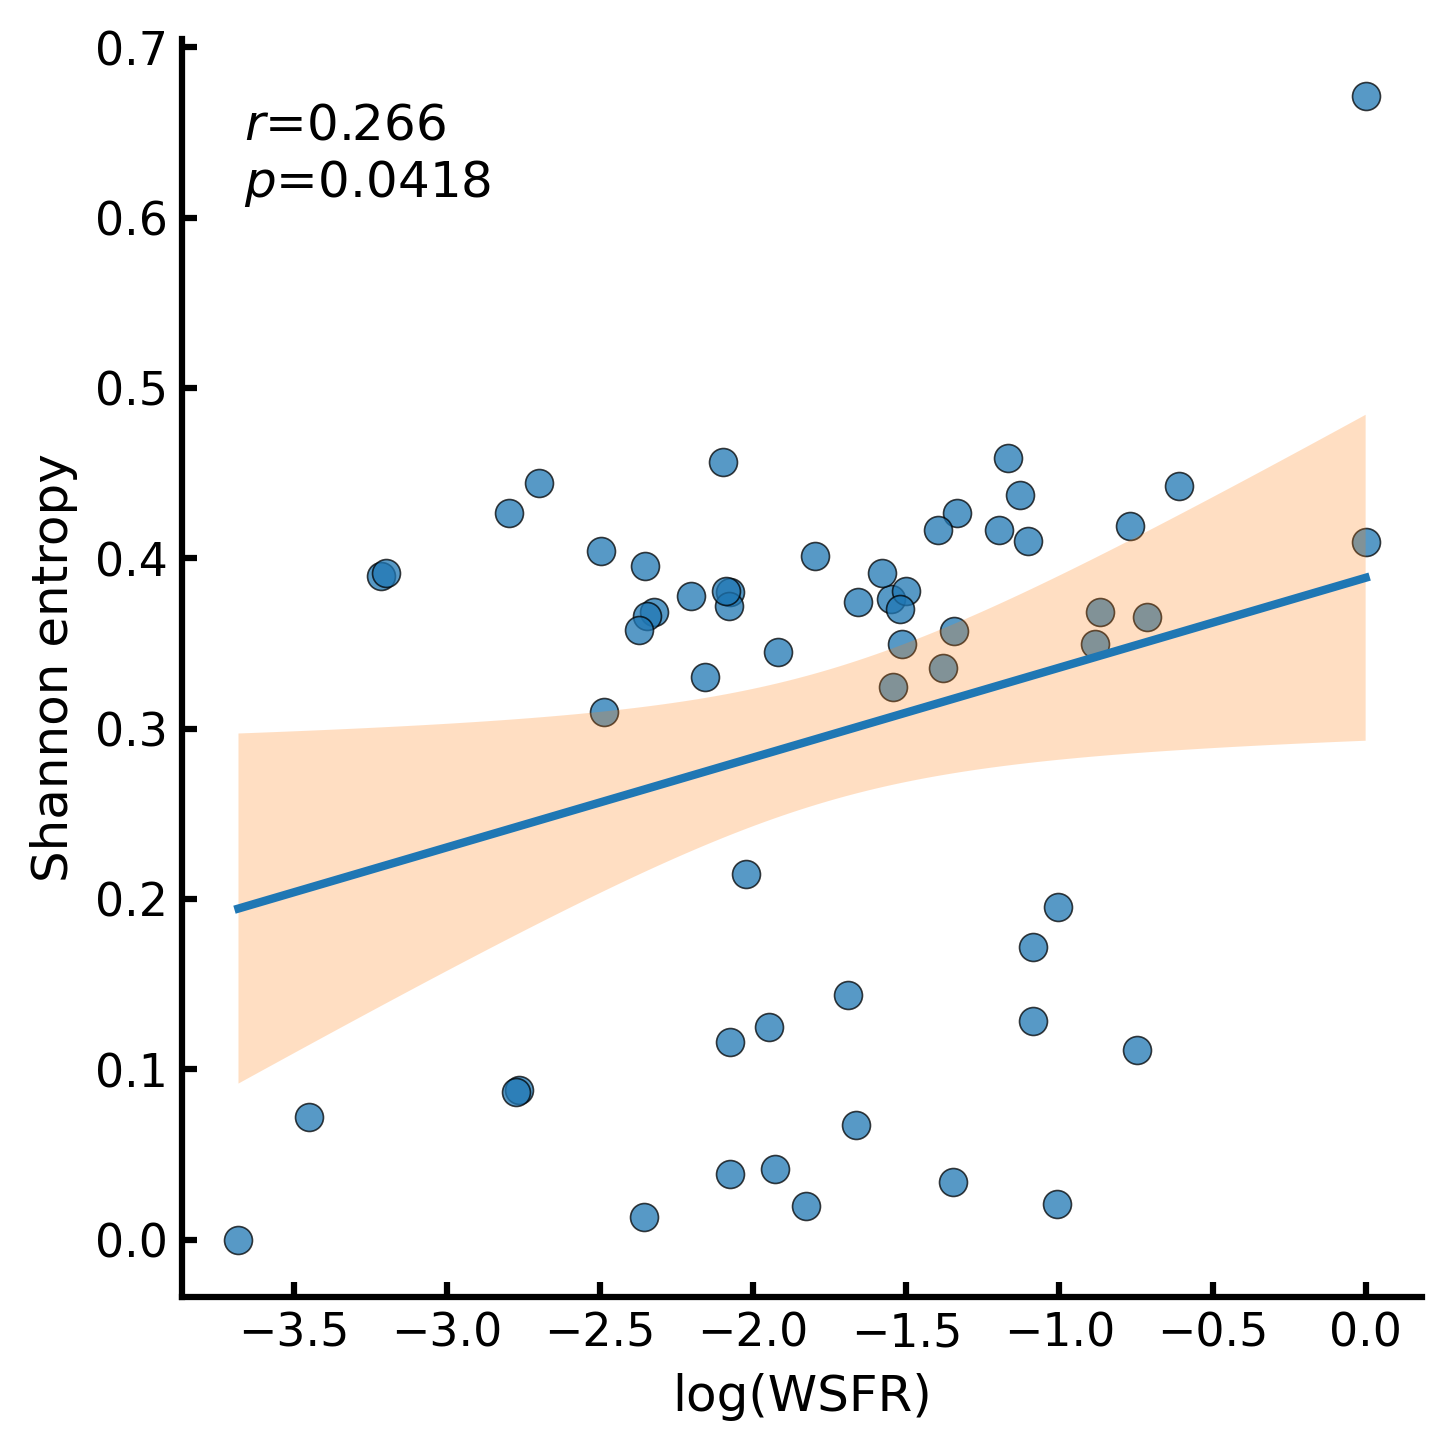

In [143]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

x=np.log(df_combined["WSFR"].values)
y=df_combined["Shannon_Entropy"].values
r,p=stats.pearsonr(x,y)

fig,ax=plt.subplots(figsize=(5,5),dpi=300)
ax.scatter(x,y,s=45,alpha=0.75,edgecolor="black",linewidth=0.4)

coef=np.polyfit(x,y,1)
xx=np.linspace(x.min(),x.max(),200)
yy=np.polyval(coef,xx)

res=y-np.polyval(coef,x)
n=len(x)
se=np.sqrt(np.sum(res**2)/(n-2))
ci=1.96*se*np.sqrt(1/n+(xx-x.mean())**2/np.sum((x-x.mean())**2))

ax.plot(xx,yy,linewidth=2)
ax.fill_between(xx,yy-ci,yy+ci,alpha=0.25)

ax.text(0.05,0.95,f"$r$={r:.3f}\n$p$={p:.4f}",transform=ax.transAxes,va="top",fontsize=12)
ax.set_xlabel("log(WSFR)",fontsize=12)
ax.set_ylabel("Shannon entropy",fontsize=12)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(labelsize=11)

plt.tight_layout()
plt.savefig("log_WSFR_vs_Shannon_Entropy.png",dpi=600,bbox_inches="tight",transparent=False)
plt.show()

Partial correlation: r=0.267, p=0.0409


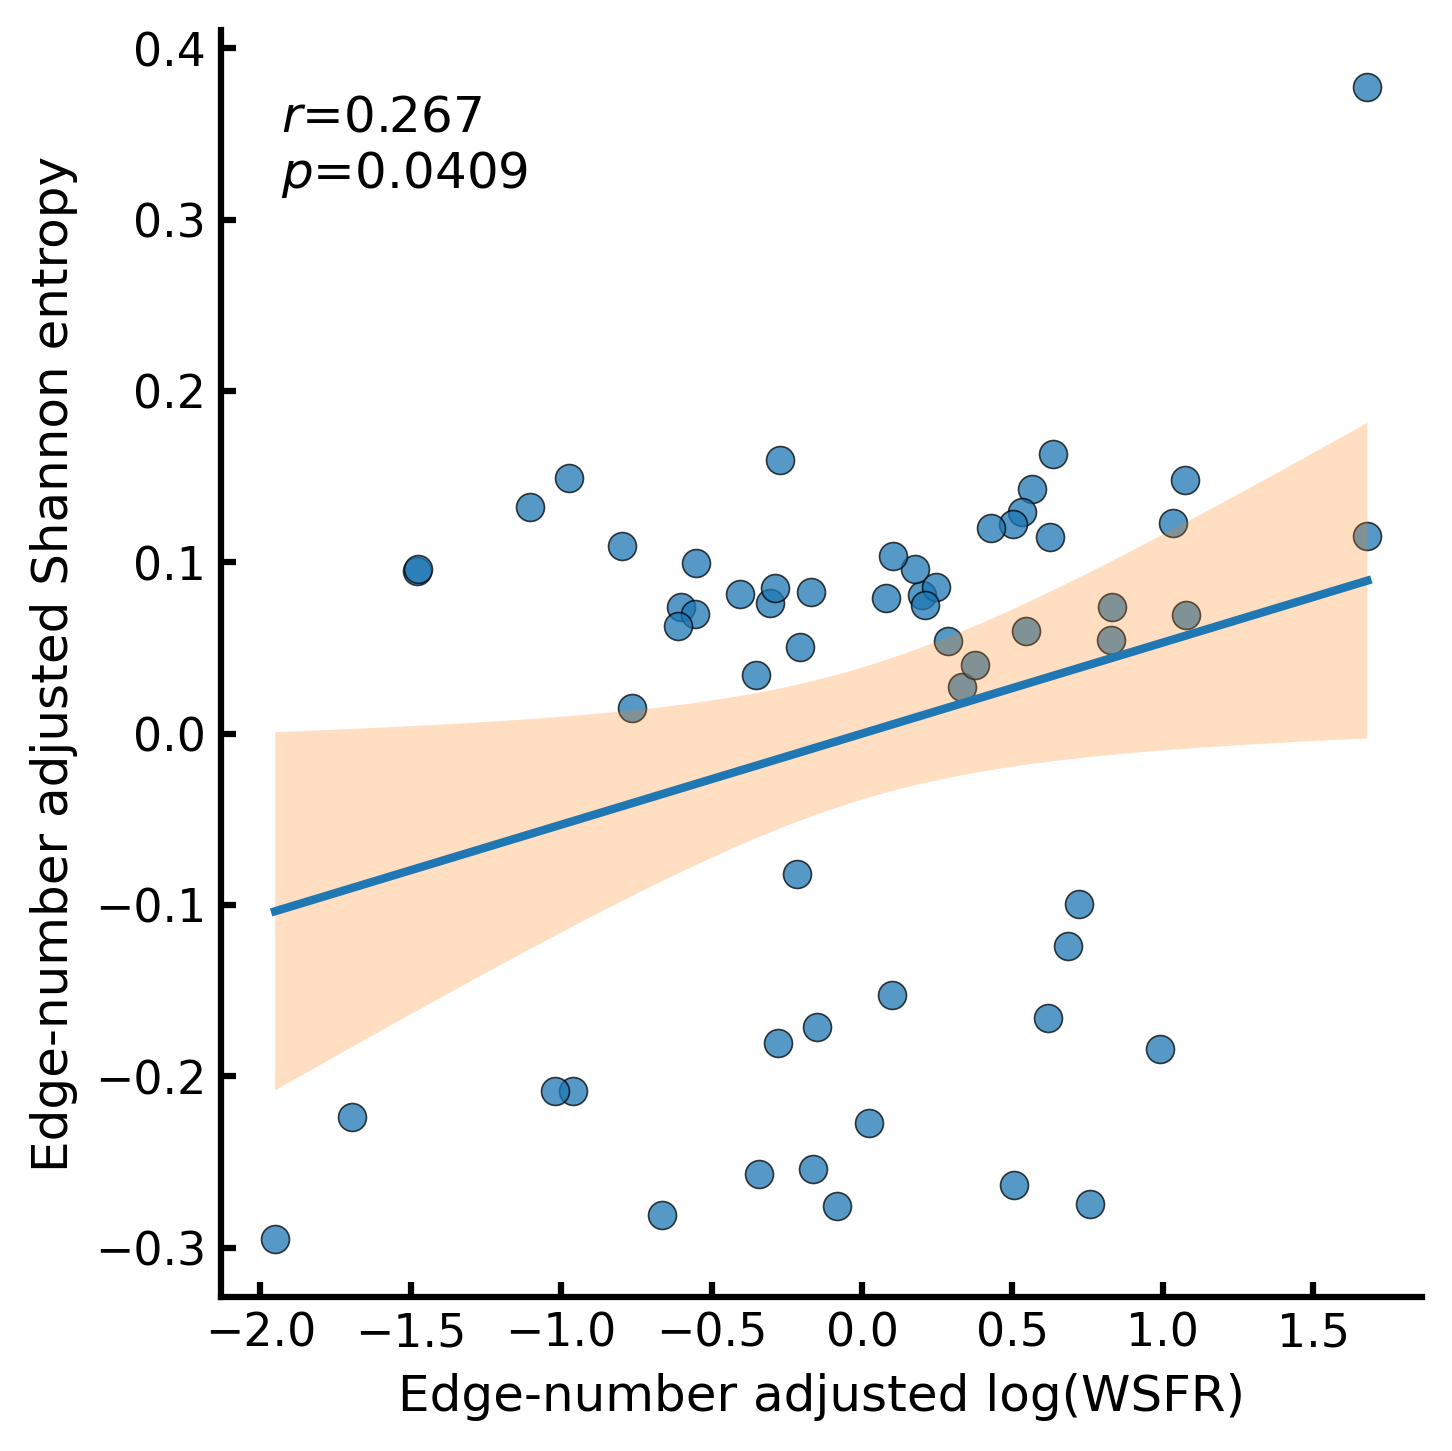

In [123]:
import numpy as np
import pandas as pd
from scipy.stats import pearsonr
import matplotlib.pyplot as plt


df = df_combined.copy()

df = df.replace([np.inf, -np.inf], np.nan)
df = df.dropna(
    subset=["WSFR", "Shannon_Entropy", "total_nonzero"]
)

# log transform
df["log_WSFR"] = np.log(df["WSFR"])


def residualize(y, z):
    z = np.column_stack([np.ones(len(z)),z])

    beta = np.linalg.lstsq(z,y,rcond=None)[0]

    y_pred = z @ beta

    return y - y_pred


x = df["log_WSFR"].values
y = df["Shannon_Entropy"].values
z = df["total_nonzero"].values


x_res = residualize(x,z)

y_res = residualize(y,z)


r, p = pearsonr(x_res,y_res)

print(f"Partial correlation: r={r:.3f}, p={p:.4f}")


# =========================
# plot
# =========================

import numpy as np
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(5,5), dpi=300)

ax.scatter(x_res, y_res, s=45, alpha=0.75, edgecolor="black", linewidth=0.4)

coef = np.polyfit(x_res, y_res, 1)
xx = np.linspace(x_res.min(), x_res.max(), 200)
yy = np.polyval(coef, xx)

residuals = y_res - np.polyval(coef, x_res)
n = len(x_res)
s_err = np.sqrt(np.sum(residuals**2)/(n-2))
x_mean = np.mean(x_res)
sxx = np.sum((x_res-x_mean)**2)

ci = 1.96*s_err*np.sqrt(1/n+(xx-x_mean)**2/sxx)

ax.plot(xx, yy, linewidth=2)
ax.fill_between(xx, yy-ci, yy+ci, alpha=0.25)

ax.text(
    0.05, 0.95,
    f"$r$={r:.3f}\n$p$={p:.4f}",
    transform=ax.transAxes,
    ha="left",
    va="top",
    fontsize=12
)

ax.set_xlabel("Edge-number adjusted log(WSFR)", fontsize=12)
ax.set_ylabel("Edge-number adjusted Shannon entropy", fontsize=12)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(labelsize=11)

plt.tight_layout()

plt.savefig(
    "partial_correlation_WSFR_entropy.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

Partial correlation: r=0.274, p=0.0359


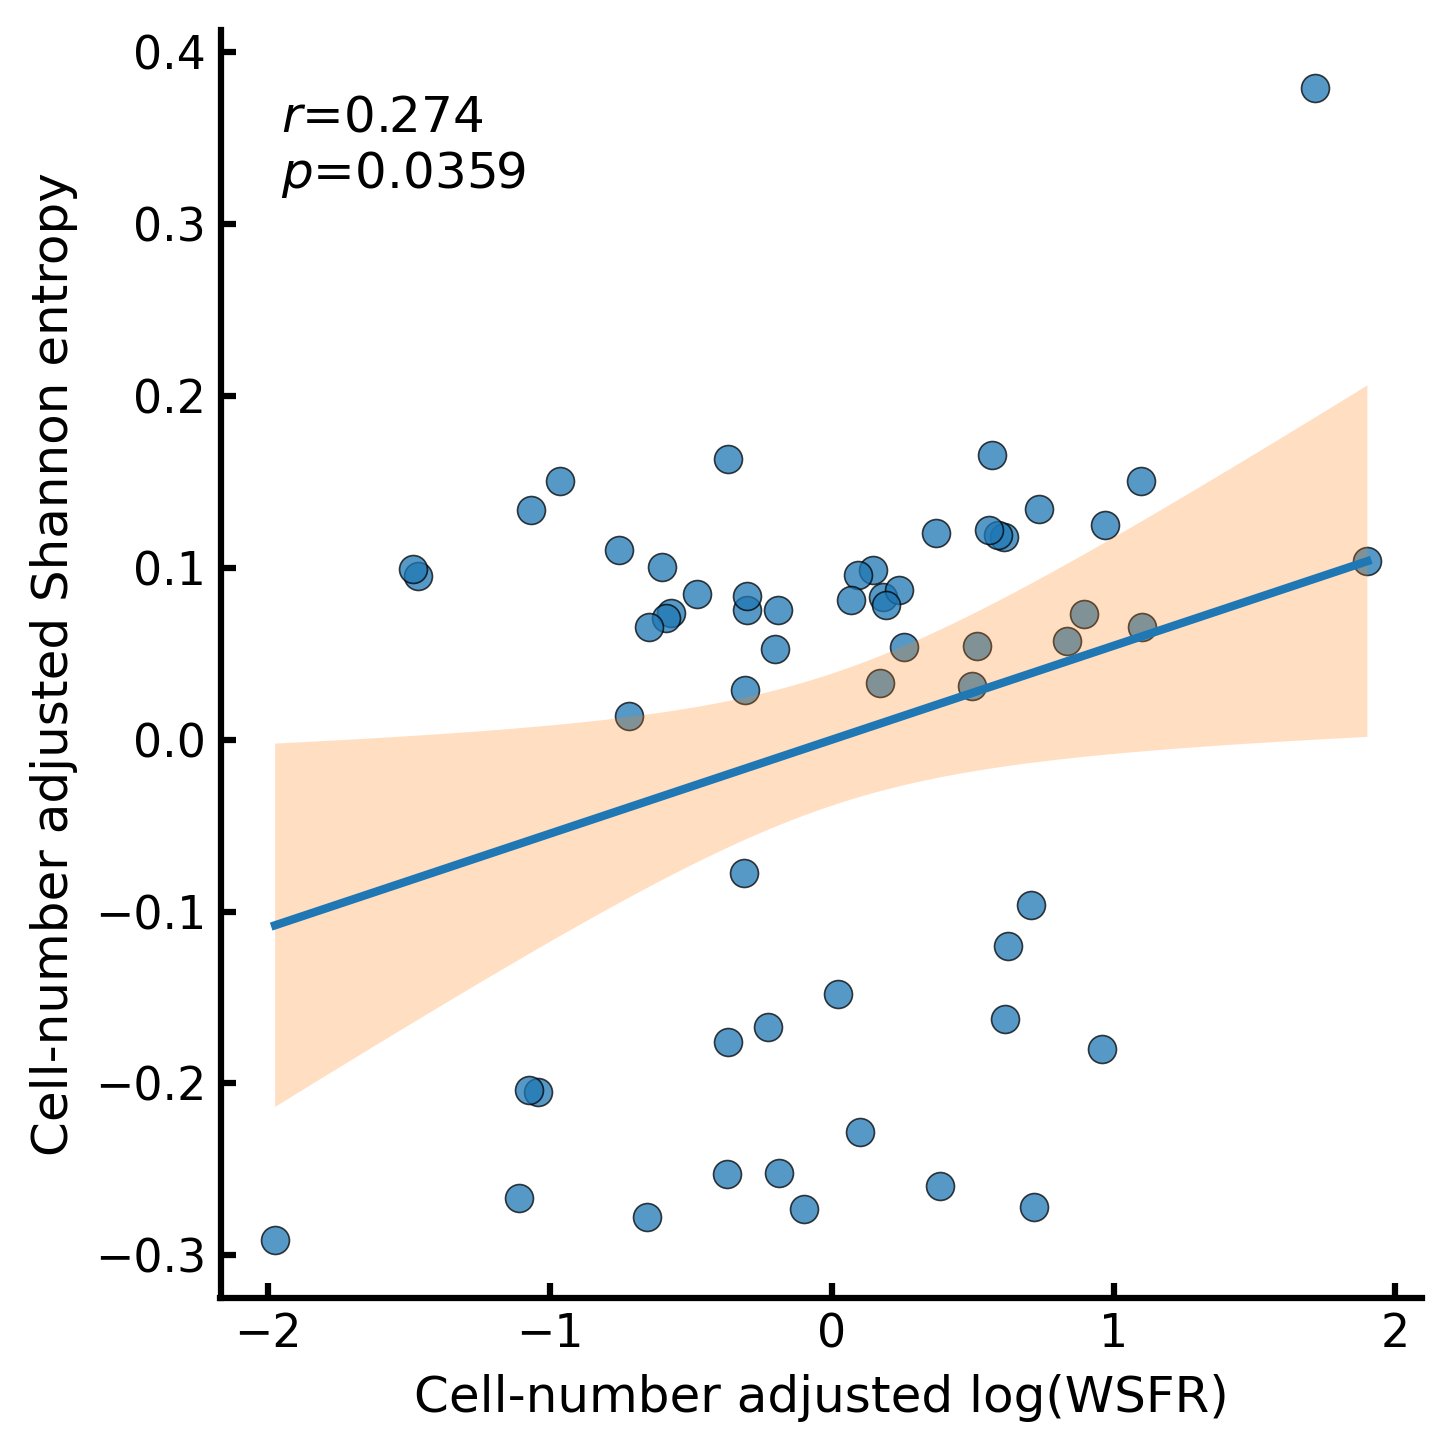

In [124]:
import numpy as np
import pandas as pd
from scipy.stats import pearsonr
import matplotlib.pyplot as plt


df = df_combined.copy()

df = df.replace([np.inf, -np.inf], np.nan)
df = df.dropna(
    subset=["WSFR", "Shannon_Entropy", "cell_number"]
)

# log transform
df["log_WSFR"] = np.log(df["WSFR"])


def residualize(y, z):
    z = np.column_stack([np.ones(len(z)),z])

    beta = np.linalg.lstsq(z,y,rcond=None)[0]

    y_pred = z @ beta

    return y - y_pred


x = df["log_WSFR"].values
y = df["Shannon_Entropy"].values
z = df["cell_number"].values


x_res = residualize(x,z)

y_res = residualize(y,z)


r, p = pearsonr(x_res,y_res)

print(f"Partial correlation: r={r:.3f}, p={p:.4f}")


# =========================
# plot
# =========================

import numpy as np
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(5,5), dpi=300)

ax.scatter(x_res, y_res, s=45, alpha=0.75, edgecolor="black", linewidth=0.4)

coef = np.polyfit(x_res, y_res, 1)
xx = np.linspace(x_res.min(), x_res.max(), 200)
yy = np.polyval(coef, xx)

residuals = y_res - np.polyval(coef, x_res)
n = len(x_res)
s_err = np.sqrt(np.sum(residuals**2)/(n-2))
x_mean = np.mean(x_res)
sxx = np.sum((x_res-x_mean)**2)

ci = 1.96*s_err*np.sqrt(1/n+(xx-x_mean)**2/sxx)

ax.plot(xx, yy, linewidth=2)
ax.fill_between(xx, yy-ci, yy+ci, alpha=0.25)

ax.text(
    0.05, 0.95,
    f"$r$={r:.3f}\n$p$={p:.4f}",
    transform=ax.transAxes,
    ha="left",
    va="top",
    fontsize=12
)

ax.set_xlabel("Cell-number adjusted log(WSFR)", fontsize=12)
ax.set_ylabel("Cell-number adjusted Shannon entropy", fontsize=12)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(labelsize=11)

plt.tight_layout()

plt.savefig(
    "partial_correlation_WSFR_entropy_cell-number.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

Partial correlation: r=0.264, p=0.0433


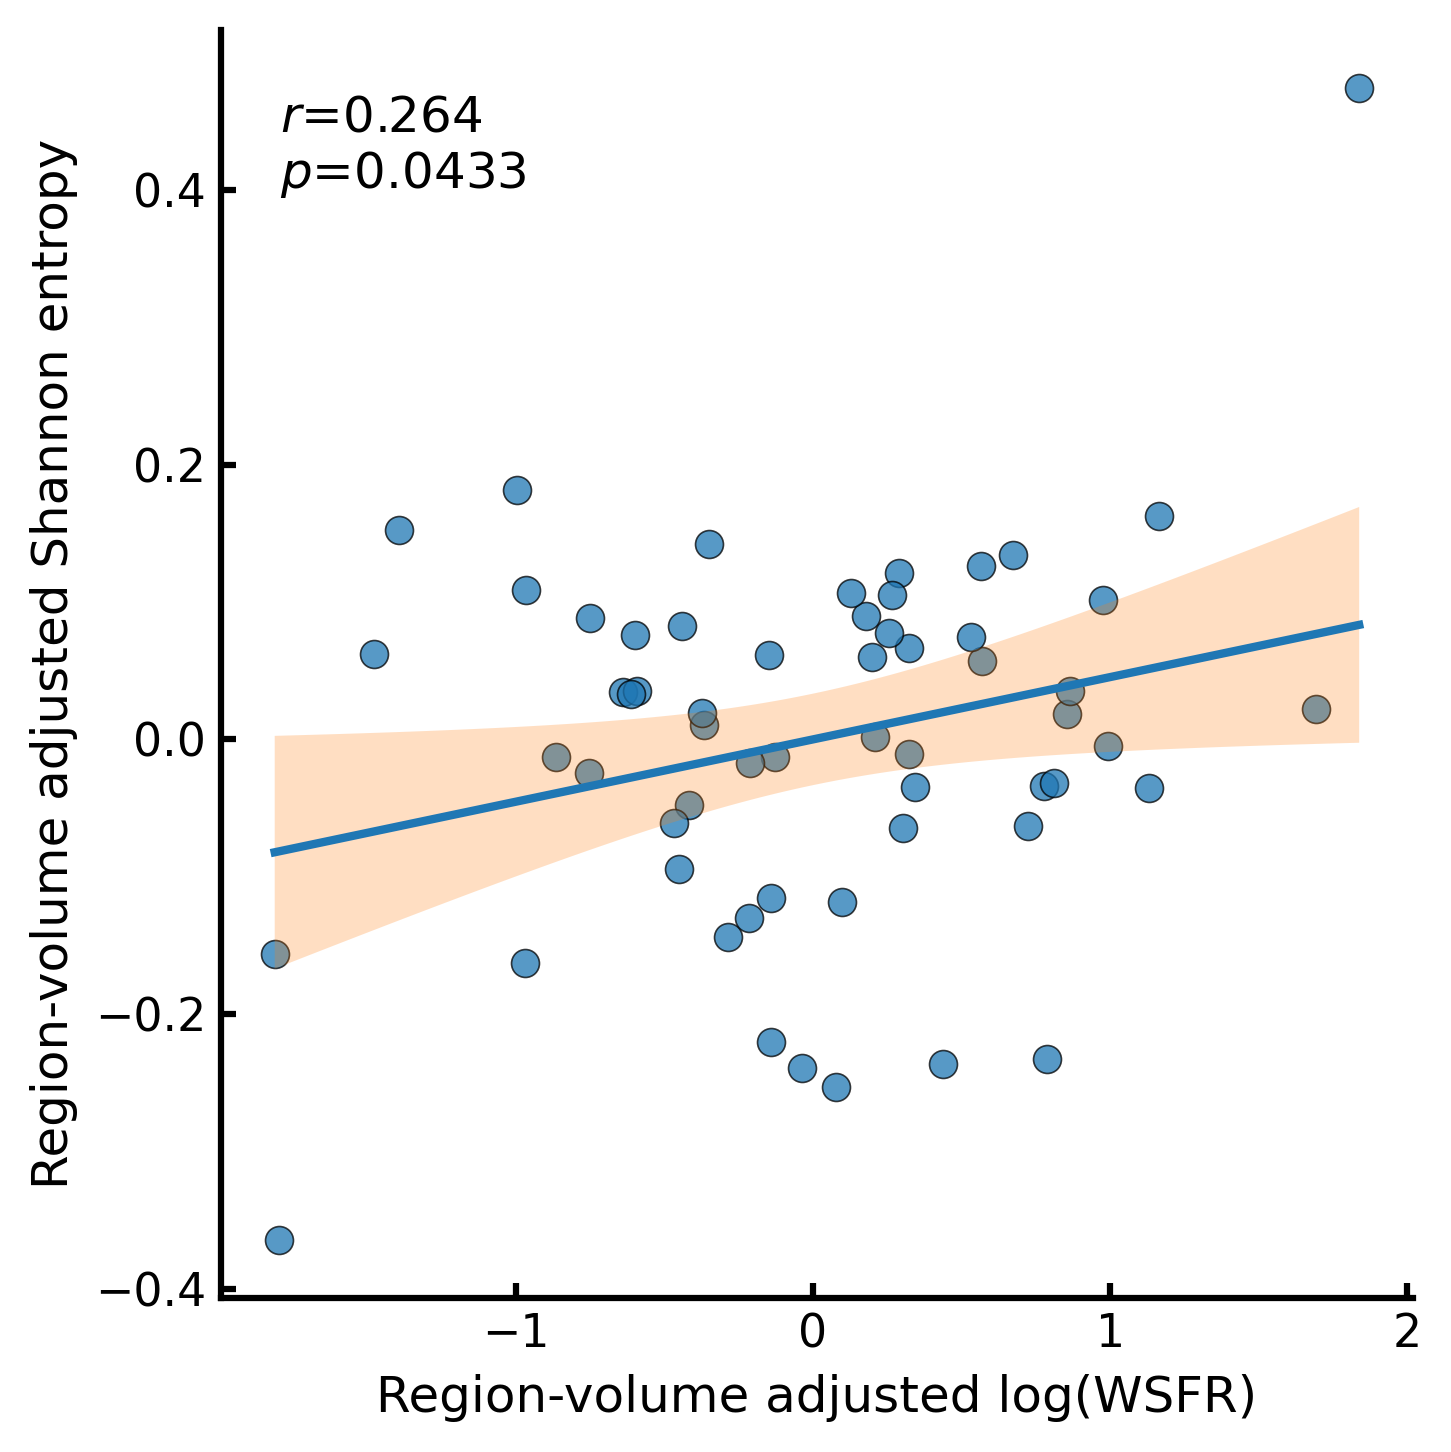

In [125]:
import numpy as np
import pandas as pd
from scipy.stats import pearsonr
import matplotlib.pyplot as plt


df = df_combined.copy()

df = df.replace([np.inf, -np.inf], np.nan)
df = df.dropna(
    subset=["WSFR", "Shannon_Entropy", "volume"]
)

# log transform
df["log_WSFR"] = np.log(df["WSFR"])


def residualize(y, z):
    z = np.column_stack([np.ones(len(z)),z])

    beta = np.linalg.lstsq(z,y,rcond=None)[0]

    y_pred = z @ beta

    return y - y_pred


x = df["log_WSFR"].values
y = df["Shannon_Entropy"].values
z = np.log(df["volume"].values)


x_res = residualize(x,z)

y_res = residualize(y,z)


r, p = pearsonr(x_res,y_res)

print(f"Partial correlation: r={r:.3f}, p={p:.4f}")


# =========================
# plot
# =========================

import numpy as np
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(5,5), dpi=300)

ax.scatter(x_res, y_res, s=45, alpha=0.75, edgecolor="black", linewidth=0.4)

coef = np.polyfit(x_res, y_res, 1)
xx = np.linspace(x_res.min(), x_res.max(), 200)
yy = np.polyval(coef, xx)

residuals = y_res - np.polyval(coef, x_res)
n = len(x_res)
s_err = np.sqrt(np.sum(residuals**2)/(n-2))
x_mean = np.mean(x_res)
sxx = np.sum((x_res-x_mean)**2)

ci = 1.96*s_err*np.sqrt(1/n+(xx-x_mean)**2/sxx)

ax.plot(xx, yy, linewidth=2)
ax.fill_between(xx, yy-ci, yy+ci, alpha=0.25)

ax.text(
    0.05, 0.95,
    f"$r$={r:.3f}\n$p$={p:.4f}",
    transform=ax.transAxes,
    ha="left",
    va="top",
    fontsize=12
)

ax.set_xlabel("Region-volume adjusted log(WSFR)", fontsize=12)
ax.set_ylabel("Region-volume adjusted Shannon entropy", fontsize=12)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(labelsize=11)

plt.tight_layout()

plt.savefig(
    "partial_correlation_WSFR_entropy_region-volume.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

Bootstrap mean r: 0.25544011648489656
90% CI: [0.00987166 0.47484023]


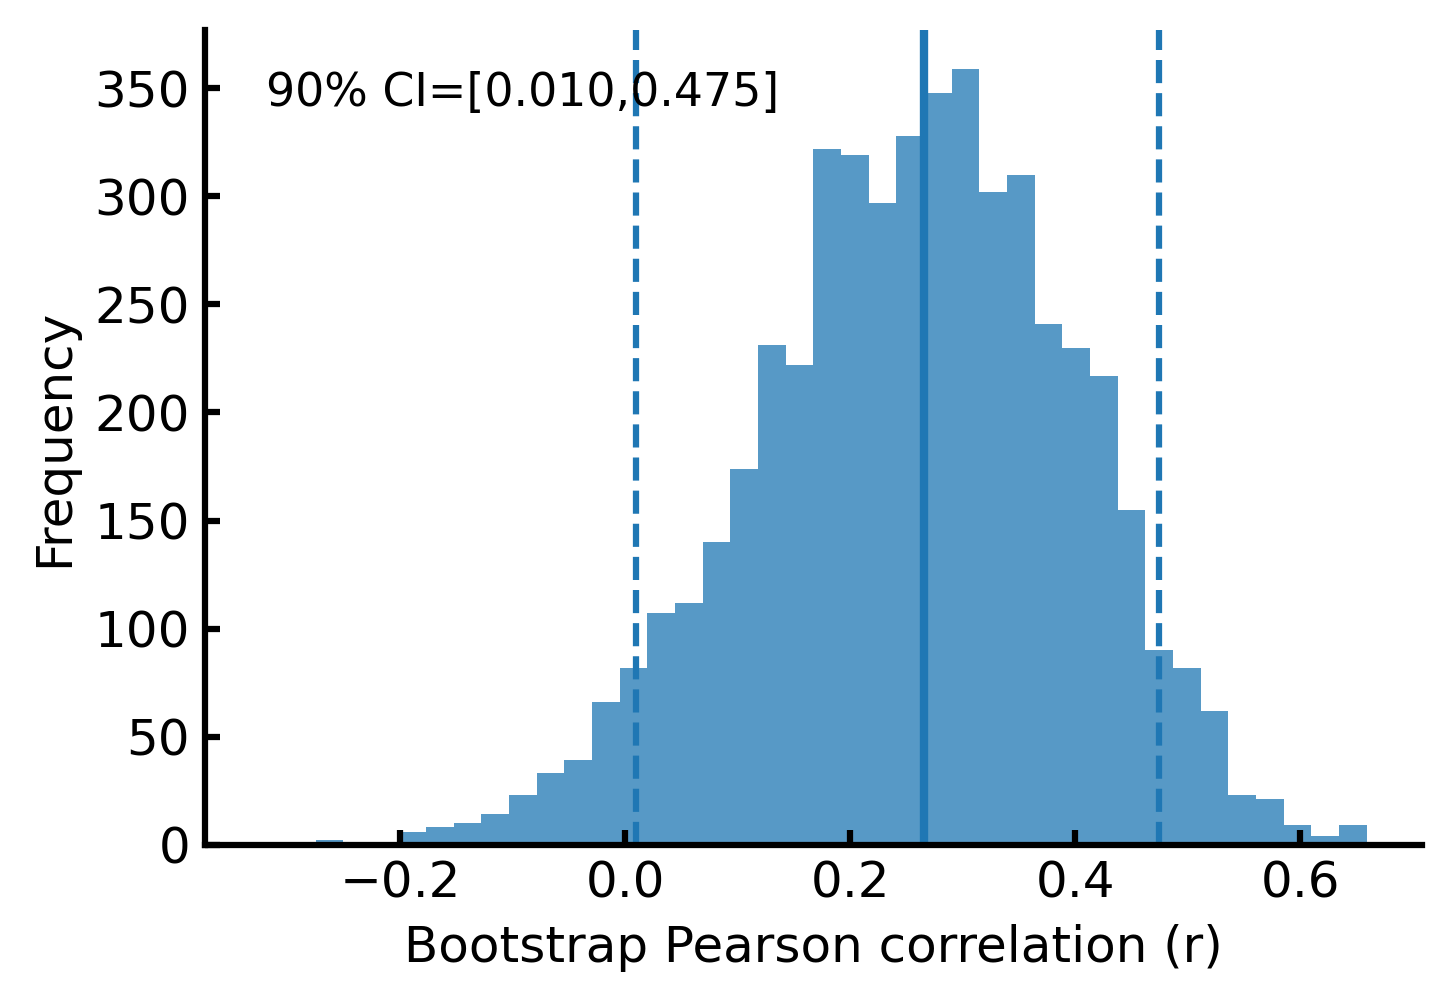

In [144]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

np.random.seed(42)

x=np.log(df_combined["WSFR"].values)
y=df_combined["Shannon_Entropy"].values

r_boot=[]
for i in range(5000):
    idx=np.random.choice(len(x),len(x),replace=True)
    r_boot.append(pearsonr(x[idx],y[idx])[0])

r_boot=np.array(r_boot)
obs_r=pearsonr(x,y)[0]
ci=np.percentile(r_boot,[5,95])

print("Bootstrap mean r:",r_boot.mean())
print("90% CI:",ci)

fig,ax=plt.subplots(figsize=(5,3.5),dpi=300)

ax.hist(r_boot,bins=40,alpha=0.75)
ax.axvline(obs_r,linewidth=2,label=f"Observed r={obs_r:.3f}")
ax.axvline(ci[0],ls="--",linewidth=1.5)
ax.axvline(ci[1],ls="--",linewidth=1.5)

ax.text(
    0.05,0.95,
    f"90% CI=[{ci[0]:.3f},{ci[1]:.3f}]",
    transform=ax.transAxes,
    va="top",
    fontsize=11
)

ax.set_xlabel("Bootstrap Pearson correlation (r)",fontsize=12)
ax.set_ylabel("Frequency",fontsize=12)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.savefig(
    "bootstrap_WSFR_entropy.png",
    dpi=600,
    bbox_inches="tight",
    transparent=False
)
plt.show()

original r: 0.2658383422441883
jackknife range: 0.18835156877914372 0.3067042546885731


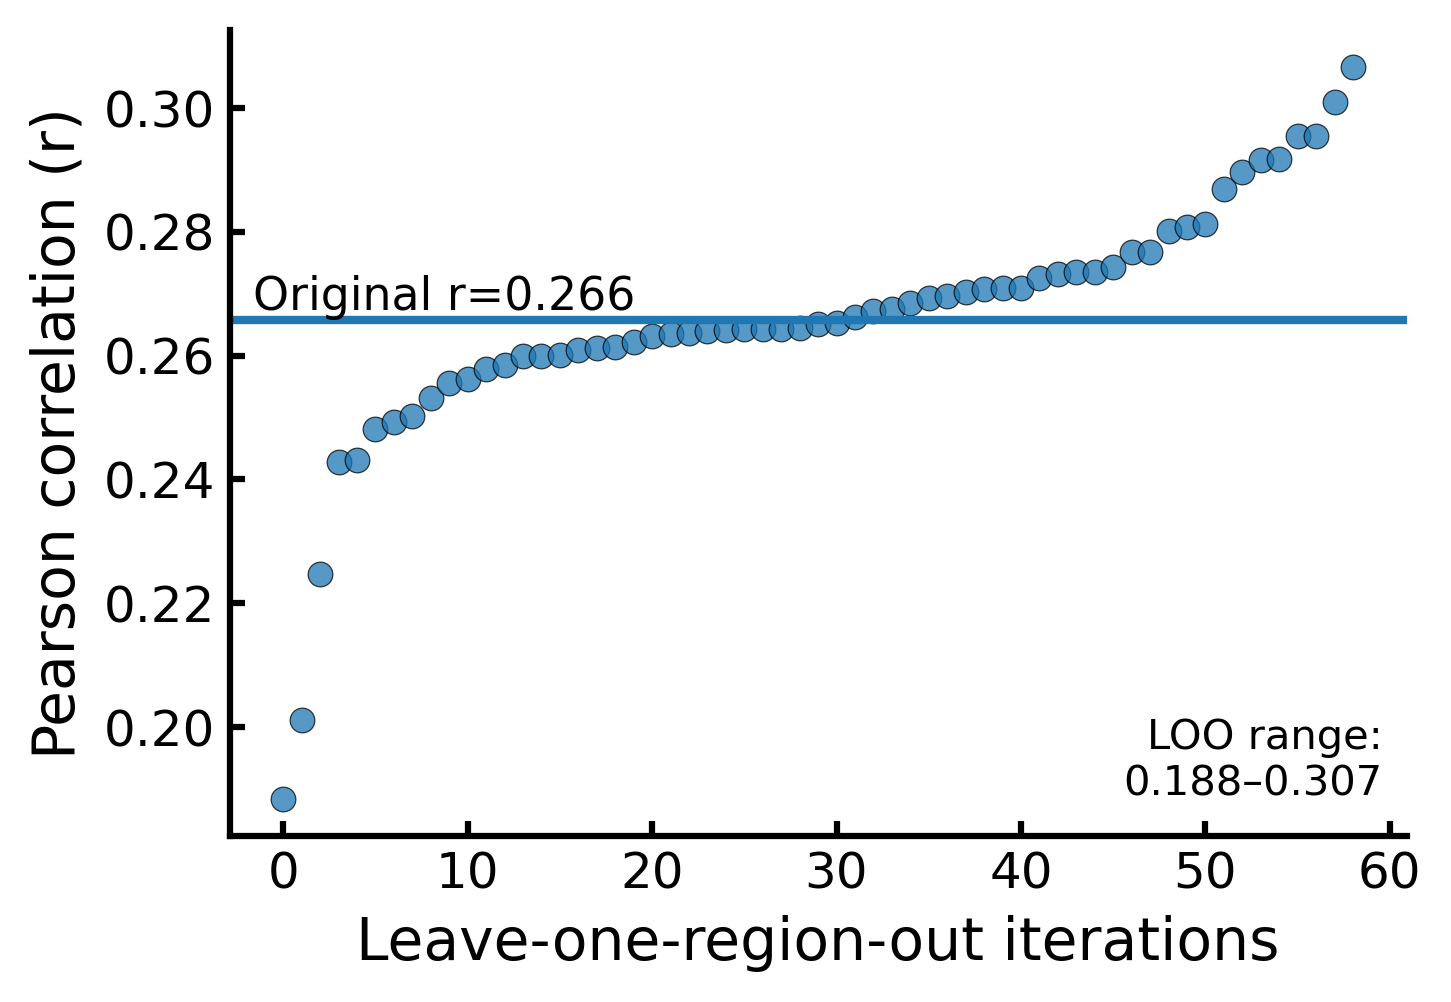

In [145]:
from scipy.stats import pearsonr
import numpy as np

x = np.log(df_combined["WSFR"].values)
y = df_combined["Shannon_Entropy"].values

r_values=[]

for i in range(len(x)):

    mask=np.ones(len(x),dtype=bool)
    mask[i]=False

    r,p=pearsonr(
        x[mask],
        y[mask]
    )

    r_values.append(r)


print("original r:",pearsonr(x,y)[0])

print("jackknife range:",min(r_values),max(r_values))

r_values=np.array(r_values)
r_obs=pearsonr(x,y)[0]
r_sort=np.sort(r_values)

fig,ax=plt.subplots(figsize=(5,3.5),dpi=300)

ax.scatter(np.arange(len(r_sort)),r_sort,s=35,alpha=0.75,edgecolor="black",linewidth=0.3)
ax.axhline(r_obs,linewidth=2)

ax.text(0.02,r_obs,f"Original r={r_obs:.3f}",transform=ax.get_yaxis_transform(),va="bottom",fontsize=11)
ax.text(0.98,0.05,f"LOO range:\n{r_sort.min():.3f}–{r_sort.max():.3f}",
        transform=ax.transAxes,ha="right",fontsize=10)

ax.set(xlabel="Leave-one-region-out iterations",ylabel="Pearson correlation (r)")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.savefig("jackknife_WSFR_entropy.png",dpi=600,bbox_inches="tight",transparent=False)
plt.show()

## 2. Gene

In [130]:
import numpy as np
import pandas as pd

def compute_signed_inout(adj, labels):
    adj = np.array(adj)

    out_degree = adj.sum(axis=1)   
    in_degree  = adj.sum(axis=0)   

    df = pd.DataFrame({
        "region": labels,
        "out_degree_signed": out_degree,
        "in_degree_signed": in_degree
    })

    df = df.set_index("region")
    df.index.name = ""

    return df

df_deg_A1 = compute_signed_inout(A1, L1)
df_deg_A2 = compute_signed_inout(A2, L2)
df_deg_A3 = compute_signed_inout(A3, L3)

In [131]:
df_deg_A1

,out_degree_signed,in_degree_signed
,,
FRP,-0.329790,0.581228
MOp,2.236550,-1.105849
MOs,2.628583,1.523244
SSp-n,1.971110,2.434170
SSp-bfd,0.852047,7.161354
...,...,...
RT,1.994945,2.641943
PSV,0.485453,0.000000
PB,0.999618,0.000000


In [132]:
df_genes = pd.read_csv("../transcriptome/merfish/merfish_group_by_region.csv")
df_genes.set_index(df_genes.columns[0], inplace=True)

df_merged_1 = df_deg_A1.join(df_genes, how="left")
############################################################################
import scipy.stats as stats

correlations = []

for gene in df_merged_1.columns:
    if gene not in ["out_degree_signed", "region", "in_degree_signed"]:
        r_value, p_value = stats.pearsonr(df_merged_1[gene], df_merged_1["out_degree_signed"])
        if p_value < 0.05:
            correlations.append({
                "gene": gene,
                "r_value": r_value,
                "p_value": p_value
            })

df_correlations = pd.DataFrame(correlations)

df_correlations_sorted = df_correlations.reindex(df_correlations["r_value"].abs().sort_values(ascending=False).index)

df_correlations_sorted

,gene,r_value,p_value
15,Lmo1,-0.278454,0.008235
24,Mdga1,-0.278420,0.008243
30,Eomes,-0.276628,0.008684
28,Npbwr1,-0.260672,0.013617
1,Rgs4,0.242883,0.021824
18,Dsg2,-0.241135,0.022821
22,Adamtsl1,-0.238944,0.024127
25,Adgrv1,-0.237262,0.025172
34,Blank-13,0.236671,0.025548
0,Rxfp3,-0.236128,0.025898


In [133]:
df_genes = pd.read_csv("../transcriptome/merfish/merfish_group_by_region.csv")
df_genes.set_index(df_genes.columns[0], inplace=True)

df_merged_2 = df_deg_A2.join(df_genes, how="left")
################################################################################
import scipy.stats as stats

correlations = []

for gene in df_merged_2.columns:
    if gene not in ["out_degree_signed", "region", "in_degree_signed"]:
        r_value, p_value = stats.pearsonr(df_merged_2[gene], df_merged_2["out_degree_signed"])
        if p_value < 0.05:
            correlations.append({
                "gene": gene,
                "r_value": r_value,
                "p_value": p_value
            })

df_correlations2 = pd.DataFrame(correlations)

df_correlations_sorted2 = df_correlations2.reindex(df_correlations2["r_value"].abs().sort_values(ascending=False).index)

df_correlations_sorted2

,gene,r_value,p_value
31,Medag,0.440435,0.000016
90,Egfem1,-0.423675,0.000035
122,Blank-13,0.407136,0.000075
10,Rorb,0.405372,0.000081
123,Blank-38,0.396436,0.000120
...,...,...,...
14,Epha4,0.211498,0.046632
81,Plpp4,-0.211022,0.047139
19,Lhfp,0.210529,0.047670
47,Slc17a7,0.209377,0.048928


In [134]:
df_genes = pd.read_csv("../transcriptome/merfish/merfish_group_by_region.csv")
df_genes.set_index(df_genes.columns[0], inplace=True)

df_merged_3 = df_deg_A3.join(df_genes, how="left")
################################################################################
import scipy.stats as stats

correlations = []

for gene in df_merged_3.columns:
    if gene not in ["out_degree_signed", "region", "in_degree_signed"]:
        r_value, p_value = stats.pearsonr(df_merged_3[gene], df_merged_3["out_degree_signed"])
        if p_value < 0.05:
            correlations.append({
                "gene": gene,
                "r_value": r_value,
                "p_value": p_value
            })

df_correlations3 = pd.DataFrame(correlations)

df_correlations_sorted3 = df_correlations3.reindex(df_correlations3["r_value"].abs().sort_values(ascending=False).index)

df_correlations_sorted3

,gene,r_value,p_value
88,Egfem1,-0.444730,0.000013
29,Medag,0.437394,0.000018
10,Rorb,0.418333,0.000045
118,Blank-38,0.398413,0.000110
117,Blank-13,0.389247,0.000163
...,...,...,...
37,Bmp4,0.209721,0.048550
80,Kitl,0.209528,0.048761
0,Ntn1,-0.209484,0.048810
3,Pitx2,0.209412,0.048889


<Figure size 800x800 with 0 Axes>

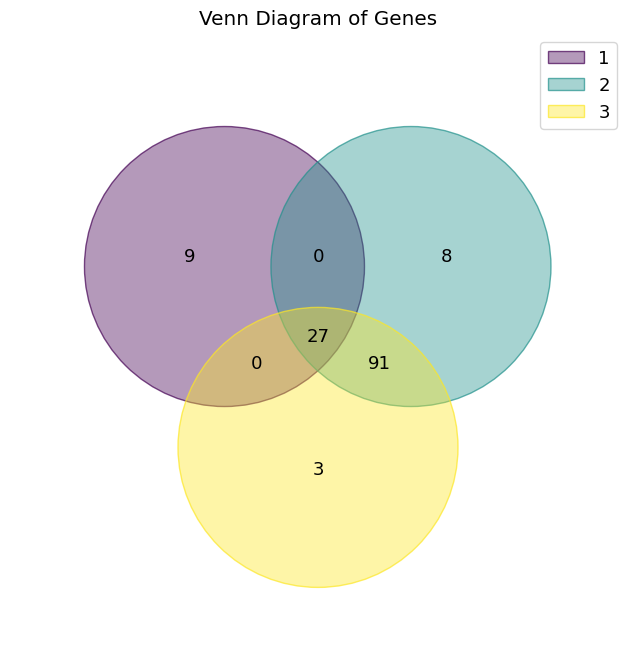

In [135]:
import matplotlib.pyplot as plt
from venn import venn

# 获取每个 DataFrame 中的基因集合
genes_1 = set(df_correlations_sorted["gene"])
genes_2 = set(df_correlations_sorted2["gene"])
genes_3 = set(df_correlations_sorted3["gene"])

# 绘制 Venn 图
plt.figure(figsize=(8, 8))
venn({1: genes_1, 2: genes_2, 3: genes_3})

# 添加标题
plt.title("Venn Diagram of Genes")

# 显示图形
plt.show()

In [136]:
genes_1 = set(df_correlations_sorted["gene"])
genes_2 = set(df_correlations_sorted2["gene"])
genes_3 = set(df_correlations_sorted3["gene"])

common_genes = genes_1 & genes_2 & genes_3

common_genes_list = list(common_genes)

print(common_genes_list)


['C1ql1', 'Nr2f1', 'Met', 'Eomes', 'Lmo1', 'Tent5a', 'Blank-33', 'G630016G05Rik', 'Rgs4', 'Blank-13', 'Npy2r', 'Popdc3', 'Adgrv1', 'Fstl5', 'Svep1', 'Gpr101', 'Adamtsl1', 'Kcng2', 'Stac', 'Ndst4', 'Trpc7', 'Rwdd2a', 'Rorb', 'Dsg2', 'Cidea', 'Nts', 'Ust']


In [137]:
df_genes = pd.read_csv("../transcriptome/merfish/merfish_group_by_region.csv")
df_genes.set_index(df_genes.columns[0], inplace=True)

df_merged_1 = df_deg_A1.join(df_genes, how="left")
############################################################################
import scipy.stats as stats

correlations = []

for gene in df_merged_1.columns:
    if gene not in ["out_degree_signed", "region", "in_degree_signed"]:
        r_value, p_value = stats.pearsonr(df_merged_1[gene], df_merged_1["in_degree_signed"])
        if p_value < 0.05:
            correlations.append({
                "gene": gene,
                "r_value": r_value,
                "p_value": p_value
            })

df_correlations = pd.DataFrame(correlations)

df_correlations_sorted = df_correlations.reindex(df_correlations["r_value"].abs().sort_values(ascending=False).index)

df_correlations_sorted

,gene,r_value,p_value
26,Blank-13,0.383086,0.000211
3,Rgs4,0.368577,0.000379
1,Pitx2,0.361410,0.000502
14,Rspo1,0.299433,0.004363
21,Grik1,-0.273974,0.009376
8,Syndig1,0.265650,0.011866
24,Blank-7,0.264835,0.012139
20,Gpr139,0.256707,0.015167
10,Bmp4,0.252664,0.016902
19,Pde11a,-0.252098,0.017158


In [138]:
df_genes = pd.read_csv("../transcriptome/merfish/merfish_group_by_region.csv")
df_genes.set_index(df_genes.columns[0], inplace=True)

df_merged_2 = df_deg_A2.join(df_genes, how="left")
################################################################################
import scipy.stats as stats

correlations = []

for gene in df_merged_2.columns:
    if gene not in ["out_degree_signed", "region", "in_degree_signed"]:
        r_value, p_value = stats.pearsonr(df_merged_2[gene], df_merged_2["in_degree_signed"])
        if p_value < 0.05:
            correlations.append({
                "gene": gene,
                "r_value": r_value,
                "p_value": p_value
            })

df_correlations2 = pd.DataFrame(correlations)

df_correlations_sorted2 = df_correlations2.reindex(df_correlations2["r_value"].abs().sort_values(ascending=False).index)

df_correlations_sorted2

,gene,r_value,p_value
4,Rgs4,0.432914,0.000023
61,Blank-13,0.420620,0.000041
22,Bmp4,0.360230,0.000525
59,Blank-7,0.359703,0.000536
32,Clic5,0.359285,0.000545
...,...,...,...
15,Cnr1,0.211668,0.046452
31,Ptk2b,0.210796,0.047382
10,Nrn1,0.210656,0.047532
42,Wls,0.209382,0.048922


In [139]:
df_genes = pd.read_csv("../transcriptome/merfish/merfish_group_by_region.csv")
df_genes.set_index(df_genes.columns[0], inplace=True)

df_merged_3 = df_deg_A3.join(df_genes, how="left")
################################################################################
import scipy.stats as stats

correlations = []

for gene in df_merged_3.columns:
    if gene not in ["out_degree_signed", "region", "in_degree_signed"]:
        r_value, p_value = stats.pearsonr(df_merged_3[gene], df_merged_3["in_degree_signed"])
        if p_value < 0.05:
            correlations.append({
                "gene": gene,
                "r_value": r_value,
                "p_value": p_value
            })

df_correlations3 = pd.DataFrame(correlations)

df_correlations_sorted3 = df_correlations3.reindex(df_correlations3["r_value"].abs().sort_values(ascending=False).index)

df_correlations_sorted3

,gene,r_value,p_value
4,Rgs4,0.429083,0.000027
73,Blank-13,0.416611,0.000049
38,Clic5,0.397263,0.000116
27,Bmp4,0.380226,0.000237
46,Arhgap15,0.367375,0.000398
...,...,...,...
14,Cacng3,0.211698,0.046420
37,Ptk2b,0.211071,0.047087
53,Plpp4,-0.210872,0.047300
66,Trpc7,-0.209062,0.049277


<Figure size 800x800 with 0 Axes>

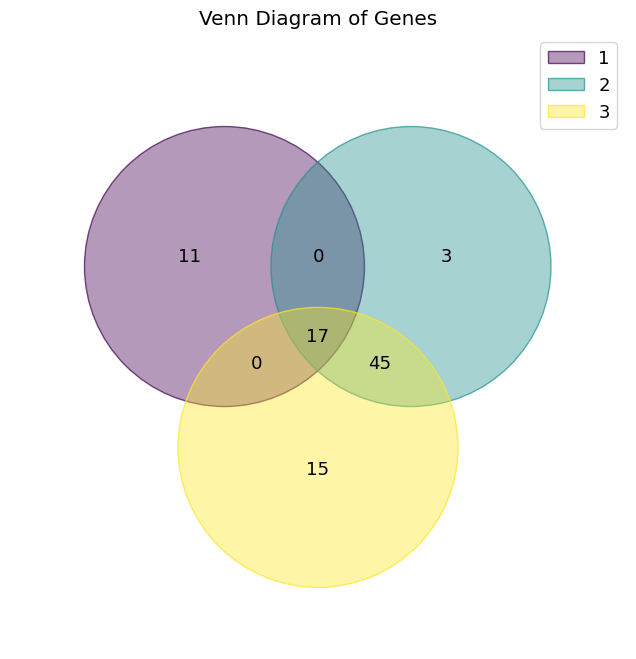

In [140]:
import matplotlib.pyplot as plt
from venn import venn

genes_1 = set(df_correlations_sorted["gene"])
genes_2 = set(df_correlations_sorted2["gene"])
genes_3 = set(df_correlations_sorted3["gene"])

plt.figure(figsize=(8, 8))
venn({1: genes_1, 2: genes_2, 3: genes_3})

plt.title("Venn Diagram of Genes")

plt.show()

In [141]:
genes_1 = set(df_correlations_sorted["gene"])
genes_2 = set(df_correlations_sorted2["gene"])
genes_3 = set(df_correlations_sorted3["gene"])

common_genes = genes_1 & genes_2 & genes_3

common_genes_list = list(common_genes)

print(common_genes_list)

['Blank-13', 'Rorb', 'Blank-32', 'Pparg', 'Blank-7', 'Dsg2', 'Grik1', 'Lamp5', 'Grm3', 'Rspo1', 'Syndig1', 'Bmp4', 'Prom1', 'Gpr139', 'Plpp4', 'Pitx2', 'Rgs4']
